
Noise = 1 arcmin
Number of reconstructed positions: 26
Minimum radius: 1.4268026517135326 AU
Median radius: 1.5387211107753278 AU
Maximum radius: 1.6071891253259258 AU


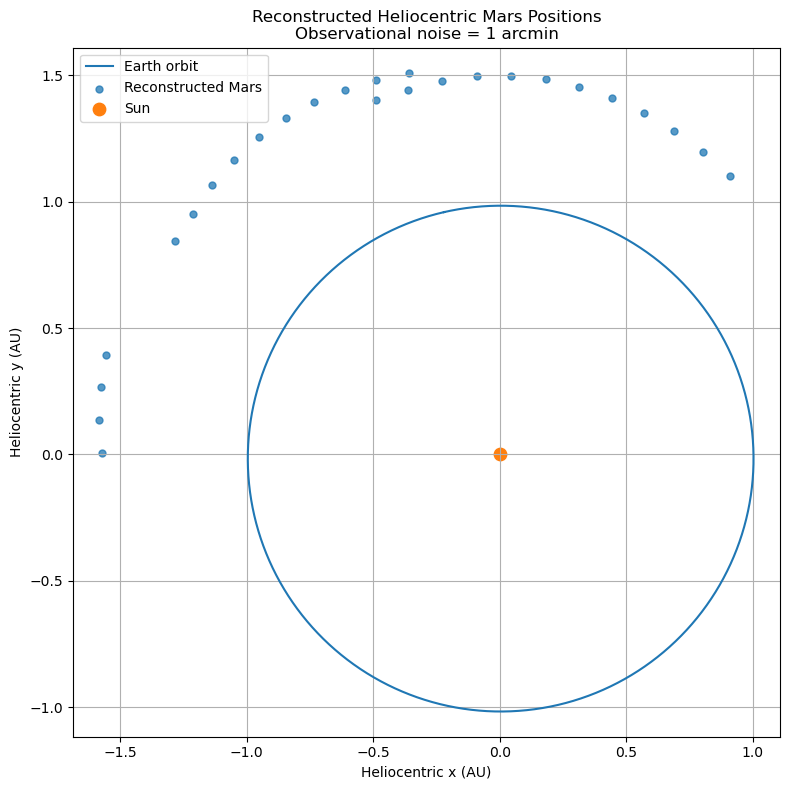


Noise = 2 arcmin
Number of reconstructed positions: 26
Minimum radius: 1.4262215519828283 AU
Median radius: 1.5380385013290931 AU
Maximum radius: 1.6071452005219815 AU


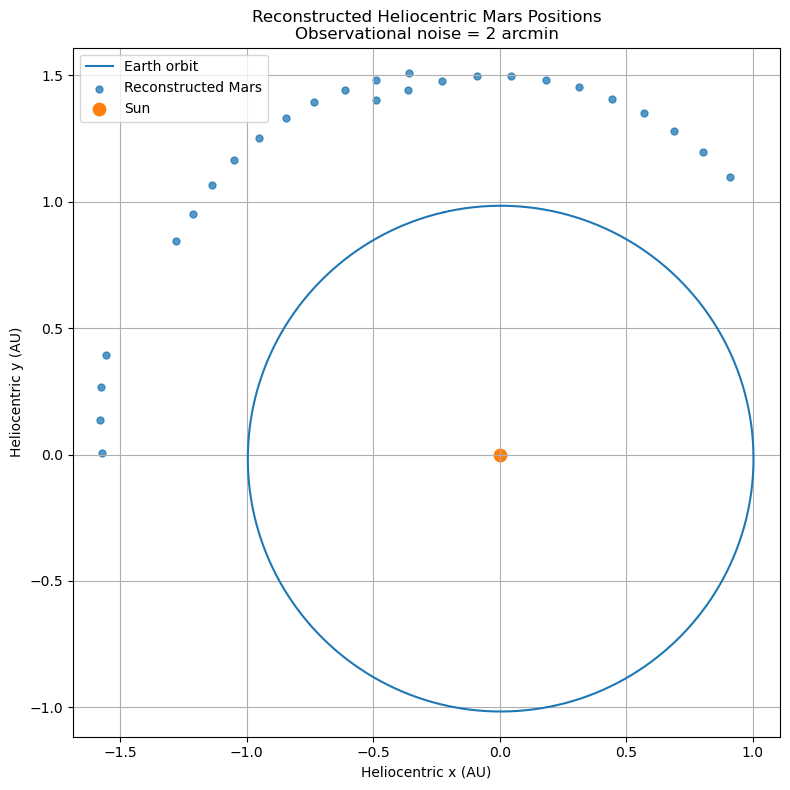


Noise = 5 arcmin
Number of reconstructed positions: 26
Minimum radius: 1.4244706616104854 AU
Median radius: 1.5358873038249268 AU
Maximum radius: 1.6070109252384879 AU


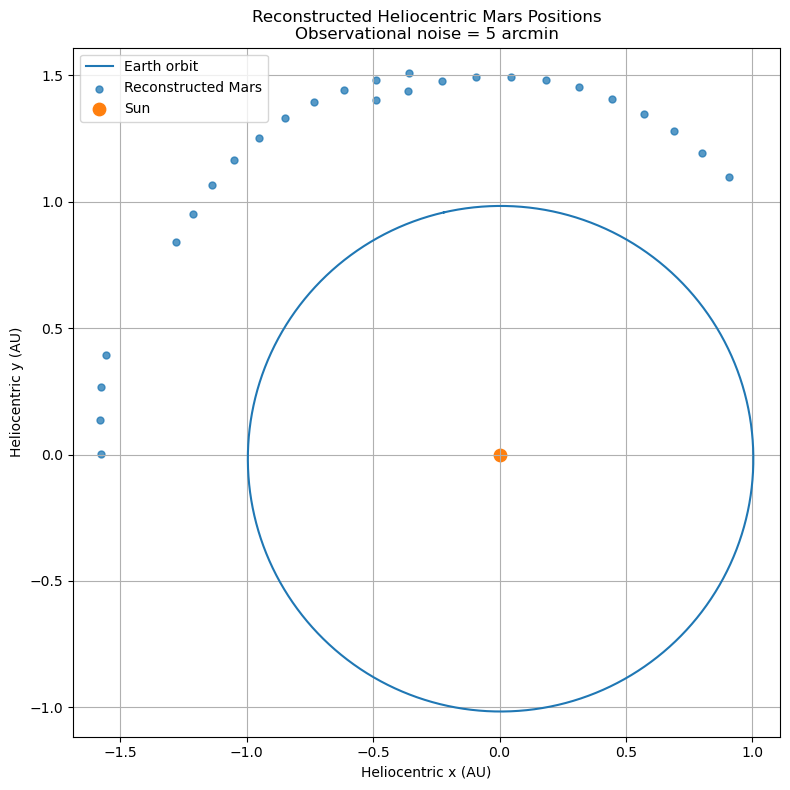

In [1]:
"""
plot_reconstructed_mars.py

Homework 1.1 - Step 5

Plot reconstructed heliocentric Mars positions together with:
    - the Sun
    - Earth's orbit

Uses:
    mars_reconstructed_1arcmin.csv
    mars_reconstructed_2arcmin.csv
    mars_reconstructed_5arcmin.csv
"""

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ============================================================
# 1. EARTH ORBIT PARAMETERS
# ============================================================

EARTH_A = 1.00000011
EARTH_E = 0.01671022

EARTH_VARPI = math.radians(
    102.93735
)


# ============================================================
# 2. GENERATE EARTH ORBIT
# ============================================================

def generate_earth_orbit(
    number_of_points=1000
):
    """
    Generate points along Earth's known Kepler ellipse.

    Uses eccentric anomaly E from 0 to 2*pi.
    """

    E = np.linspace(
        0,
        2 * np.pi,
        number_of_points
    )

    # Earth ellipse before rotation
    x = EARTH_A * (
        np.cos(E)
        - EARTH_E
    )

    y = (
        EARTH_A
        * np.sqrt(
            1 - EARTH_E**2
        )
        * np.sin(E)
    )

    # Rotate ellipse by longitude of perihelion.
    c = np.cos(
        EARTH_VARPI
    )

    s = np.sin(
        EARTH_VARPI
    )

    x_rotated = (
        c * x
        - s * y
    )

    y_rotated = (
        s * x
        + c * y
    )

    return (
        x_rotated,
        y_rotated
    )


# ============================================================
# 3. PLOT ONE RECONSTRUCTION
# ============================================================

def plot_reconstruction(
    noise_arcmin
):

    filename = (
        f"mars_reconstructed_"
        f"{noise_arcmin}arcmin.csv"
    )

    df = pd.read_csv(
        filename
    )

    earth_x, earth_y = (
        generate_earth_orbit()
    )

    # --------------------------------------------------------
    # Calculate heliocentric radius of each reconstructed point
    # --------------------------------------------------------

    df["radius_AU"] = np.sqrt(
        df["x_AU"]**2
        +
        df["y_AU"]**2
        +
        df["z_AU"]**2
    )

    print(
        "\n===================================="
    )

    print(
        f"Noise = {noise_arcmin} arcmin"
    )

    print(
        "===================================="
    )

    print(
        "Number of reconstructed positions:",
        len(df)
    )

    print(
        "Minimum radius:",
        df["radius_AU"].min(),
        "AU"
    )

    print(
        "Median radius:",
        df["radius_AU"].median(),
        "AU"
    )

    print(
        "Maximum radius:",
        df["radius_AU"].max(),
        "AU"
    )

    # ========================================================
    # PLOT
    # ========================================================

    plt.figure(
        figsize=(8, 8)
    )

    # Earth's orbit
    plt.plot(
        earth_x,
        earth_y,
        label="Earth orbit"
    )

    # Reconstructed Mars positions
    plt.scatter(
        df["x_AU"],
        df["y_AU"],
        s=25,
        alpha=0.75,
        label="Reconstructed Mars"
    )

    # Sun
    plt.scatter(
        [0],
        [0],
        s=80,
        marker="o",
        label="Sun"
    )

    plt.xlabel(
        "Heliocentric x (AU)"
    )

    plt.ylabel(
        "Heliocentric y (AU)"
    )

    plt.title(
        "Reconstructed Heliocentric Mars Positions\n"
        f"Observational noise = "
        f"{noise_arcmin} arcmin"
    )

    # Extremely important for orbital plots:
    # x and y must have the same scale.
    plt.axis(
        "equal"
    )

    plt.grid(
        True
    )

    plt.legend()

    plt.tight_layout()

    output_filename = (
        f"mars_reconstruction_"
        f"{noise_arcmin}arcmin.png"
    )

    plt.savefig(
        output_filename,
        dpi=300
    )

    plt.show()


# ============================================================
# 4. MAKE ALL THREE PLOTS
# ============================================================

for noise in [
    1,
    2,
    5
]:

    plot_reconstruction(
        noise
    )